<a href="https://colab.research.google.com/github/Singleeee/T2-IA-Classificacao/blob/main/Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tanguypledel/science-fiction-books-subgenres")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'science-fiction-books-subgenres' dataset.
Path to dataset files: /kaggle/input/science-fiction-books-subgenres


In [ ]:
import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier

%matplotlib inline
sns.set_theme(style="whitegrid")

In [ ]:
# Informe a pasta onde estão salvos os arquivos (use '.' se estiverem na mesma pasta do notebook)
caminho_pasta = '/kaggle/input/science-fiction-books-subgenres'

# Busca todos os arquivos que começam com 'sf_' e terminam com '.csv'
arquivos_csv = glob.glob(os.path.join(caminho_pasta, "sf_*.csv"))

lista_dfs = []

for arquivo in arquivos_csv:
    # Lê o CSV individual
    df_temp = pd.read_csv(arquivo)

    # Extrai o nome da classe/subgênero a partir do nome do arquivo
    # Exemplo: 'sf_cyberpunk.csv' -> 'cyberpunk'
    nome_arquivo = os.path.basename(arquivo)
    subgenero = nome_arquivo.replace('sf_', '').replace('.csv', '')

    # Cria a coluna 'subgenre' para identificar o rótulo da classe
    df_temp['subgenre'] = subgenero

    lista_dfs.append(df_temp)

# Concatena todos os DataFrames em um só
df = pd.concat(lista_dfs, ignore_index=True)

print(f"Total de arquivos unificados: {len(arquivos_csv)}")
print(f"Dimensão total do Dataset unificado: {df.shape}")
df.head()

Total de arquivos unificados: 12
Dimensão total do Dataset unificado: (14974, 12)


,Book_Title,Original_Book_Title,Author_Name,Edition_Language,Rating_score,Rating_votes,Review_number,Book_Description,Year_published,Genres,url,subgenre
0,Neuromancer,Neuromancer,William Gibson,English,3.90,268536,9800,Hotwired to the leading edges of art and techn...,1984,"{'Science Fiction': 6796, 'Fiction': 3550, 'Sc...",https://www.goodreads.com/book/show/6088007-ne...,cyberpunk
1,Snow Crash,Snow Crash,Neal Stephenson,English,4.02,241095,9391,"In reality, Hiro Protagonist delivers pizza fo...",1992,"{'Science Fiction': 5069, 'Fiction': 3067, 'Sc...",https://www.goodreads.com/book/show/40651883-s...,cyberpunk
2,Count Zero,Count Zero,William Gibson,English,4.01,46114,1219,A corporate mercenary wakes in a reconstructed...,1986,"{'Science Fiction': 1480, 'Science Fiction (Cy...",https://www.goodreads.com/book/show/22200.Coun...,cyberpunk
3,Altered Carbon,Altered Carbon,Richard K. Morgan,English,4.05,90069,5990,Four hundred years from now mankind is strung ...,2002,"{'Science Fiction': 3185, 'Fiction': 1087, 'Sc...",https://www.goodreads.com/book/show/40792913-a...,cyberpunk
4,Mona Lisa Overdrive,Mona Lisa Overdrive,William Gibson,English,3.99,37399,957,"William Gibson, author of the extraordinary mu...",1988,"{'Science Fiction': 1337, 'Science Fiction (Cy...",https://www.goodreads.com/book/show/154091.Mon...,cyberpunk


/tmp/ipykernel_4326/1536552829.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='subgenre', data=df, order=df['subgenre'].value_counts().index, palette='viridis')


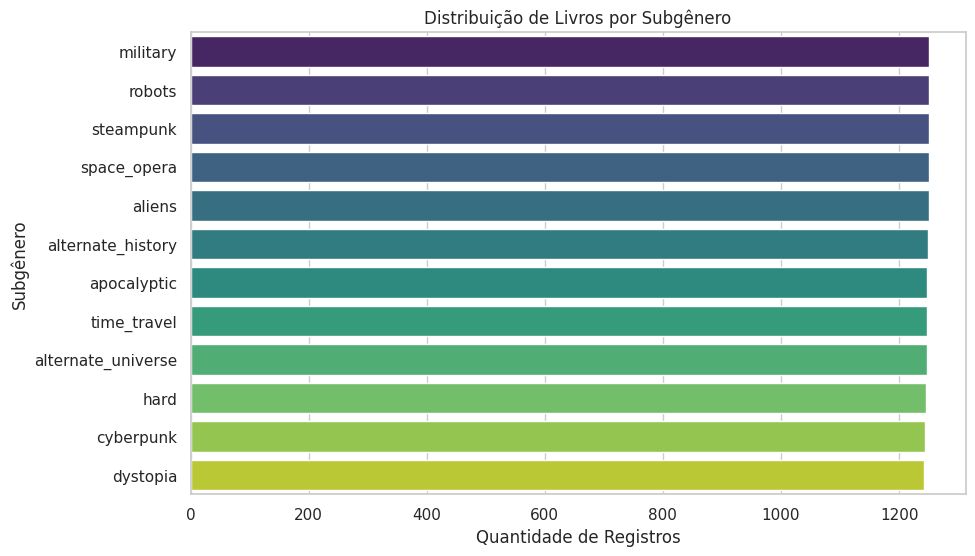

In [ ]:
# Exibir a contagem de registros por subgênero
plt.figure(figsize=(10, 6))
sns.countplot(y='subgenre', data=df, order=df['subgenre'].value_counts().index, palette='viridis')
plt.title('Distribuição de Livros por Subgênero')
plt.xlabel('Quantidade de Registros')
plt.ylabel('Subgênero')
plt.show()

# Limpeza: remover registros sem descrição ou sem classe
df = df.dropna(subset=['subgenre', 'Book_Description'])

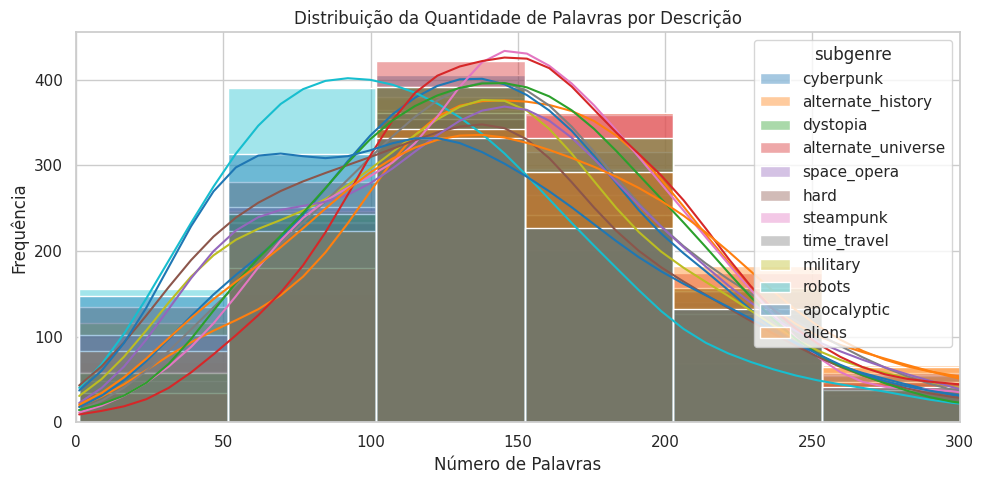

In [ ]:
df['tamanho_texto'] = df['Book_Description'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tamanho_texto', hue='subgenre', kde=True, bins=30, palette='tab10', alpha=0.4)
plt.title('Distribuição da Quantidade de Palavras por Descrição')
plt.xlabel('Número de Palavras')
plt.ylabel('Frequência')
plt.xlim(0, 300) # Limite ajustável para melhor visualização
plt.tight_layout()
plt.show()

In [ ]:
X_text = df['Book_Description'].astype(str)
y = df['subgenre']

# Mapeamento numérico das classes
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Extração de recursos textuais
tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))
X_vectorized = tfidf.fit_transform(X_text)

print(f"Formato da matriz de texto (TF-IDF): {X_vectorized.shape}")

Formato da matriz de texto (TF-IDF): (14903, 5000)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")

Treino: 11922 amostras | Teste: 2981 amostras


In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


--- Acurácia do Modelo: 38.88% ---

                    precision    recall  f1-score   support

            aliens       0.54      0.63      0.58       250
 alternate_history       0.37      0.29      0.33       250
alternate_universe       0.29      0.32      0.30       249
       apocalyptic       0.38      0.44      0.41       249
         cyberpunk       0.50      0.47      0.48       245
          dystopia       0.19      0.18      0.19       248
              hard       0.20      0.16      0.18       244
          military       0.38      0.44      0.41       250
            robots       0.53      0.38      0.44       248
       space_opera       0.22      0.24      0.23       250
         steampunk       0.47      0.47      0.47       249
       time_travel       0.56      0.65      0.60       249

          accuracy                           0.39      2981
         macro avg       0.39      0.39      0.38      2981
      weighted avg       0.39      0.39      0.38      2981



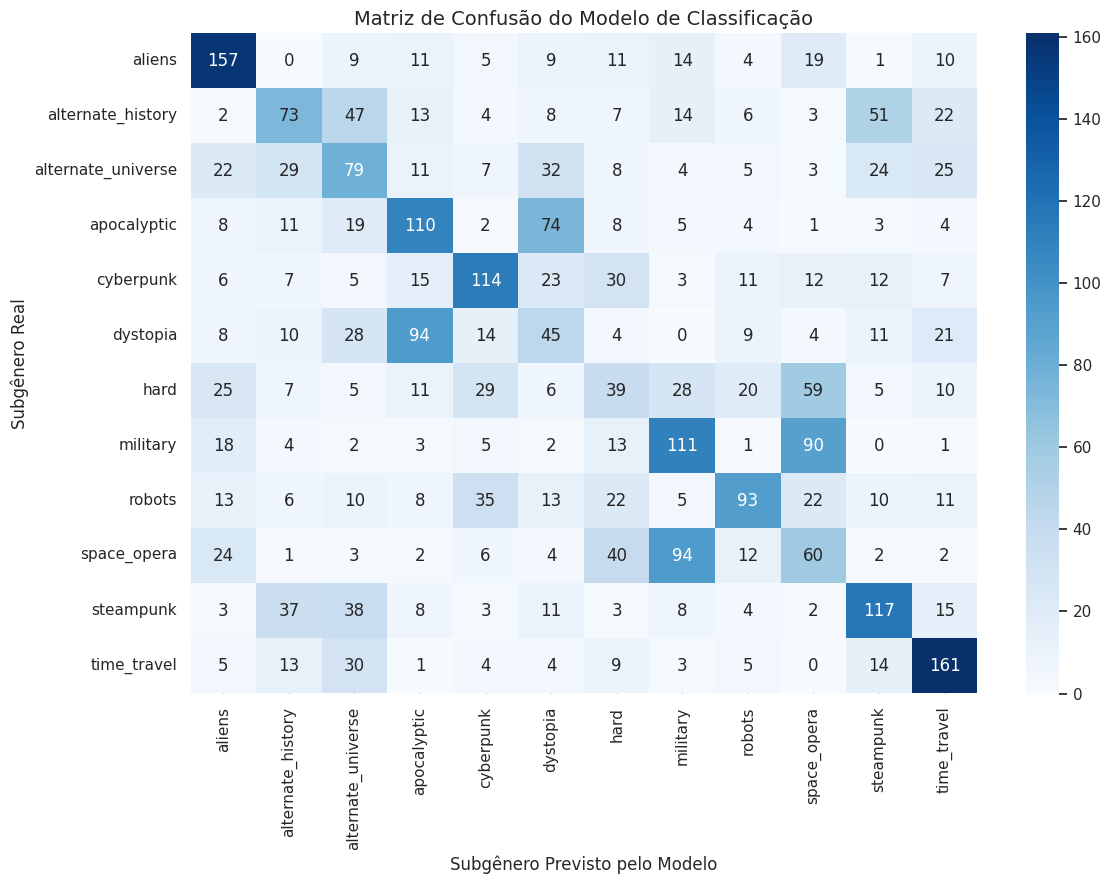

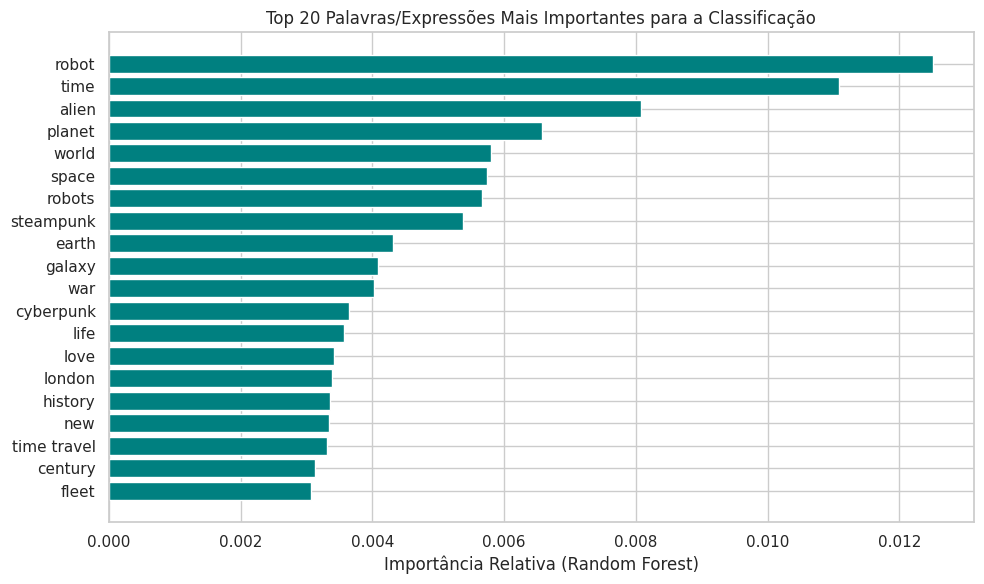

In [ ]:
y_pred = model.predict(X_test)

print(f"--- Acurácia do Modelo: {accuracy_score(y_test, y_pred) * 100:.2f}% ---\n")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Gráfico 3: Matriz de Confusão em Heatmap
plt.figure(figsize=(12, 9))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Matriz de Confusão do Modelo de Classificação', fontsize=14)
plt.xlabel('Subgênero Previsto pelo Modelo')
plt.ylabel('Subgênero Real')
plt.tight_layout()
plt.show()

# Gráfico 4: Palavras / Features mais Importantes (Feature Importance)
importances = model.feature_importances_
feature_names = tfidf.get_feature_names_out()
indices_top = np.argsort(importances)[-20:] # Top 20 palavras mais relevantes

plt.figure(figsize=(10, 6))
plt.title('Top 20 Palavras/Expressões Mais Importantes para a Classificação')
plt.barh(range(len(indices_top)), importances[indices_top], color='teal', align='center')
plt.yticks(range(len(indices_top)), [feature_names[i] for i in indices_top])
plt.xlabel('Importância Relativa (Random Forest)')
plt.tight_layout()
plt.show()

Acurácia Geral: 38.88%

Relatório de Classificação por Subgênero:
                    precision    recall  f1-score   support

            aliens       0.54      0.63      0.58       250
 alternate_history       0.37      0.29      0.33       250
alternate_universe       0.29      0.32      0.30       249
       apocalyptic       0.38      0.44      0.41       249
         cyberpunk       0.50      0.47      0.48       245
          dystopia       0.19      0.18      0.19       248
              hard       0.20      0.16      0.18       244
          military       0.38      0.44      0.41       250
            robots       0.53      0.38      0.44       248
       space_opera       0.22      0.24      0.23       250
         steampunk       0.47      0.47      0.47       249
       time_travel       0.56      0.65      0.60       249

          accuracy                           0.39      2981
         macro avg       0.39      0.39      0.38      2981
      weighted avg       0.39   

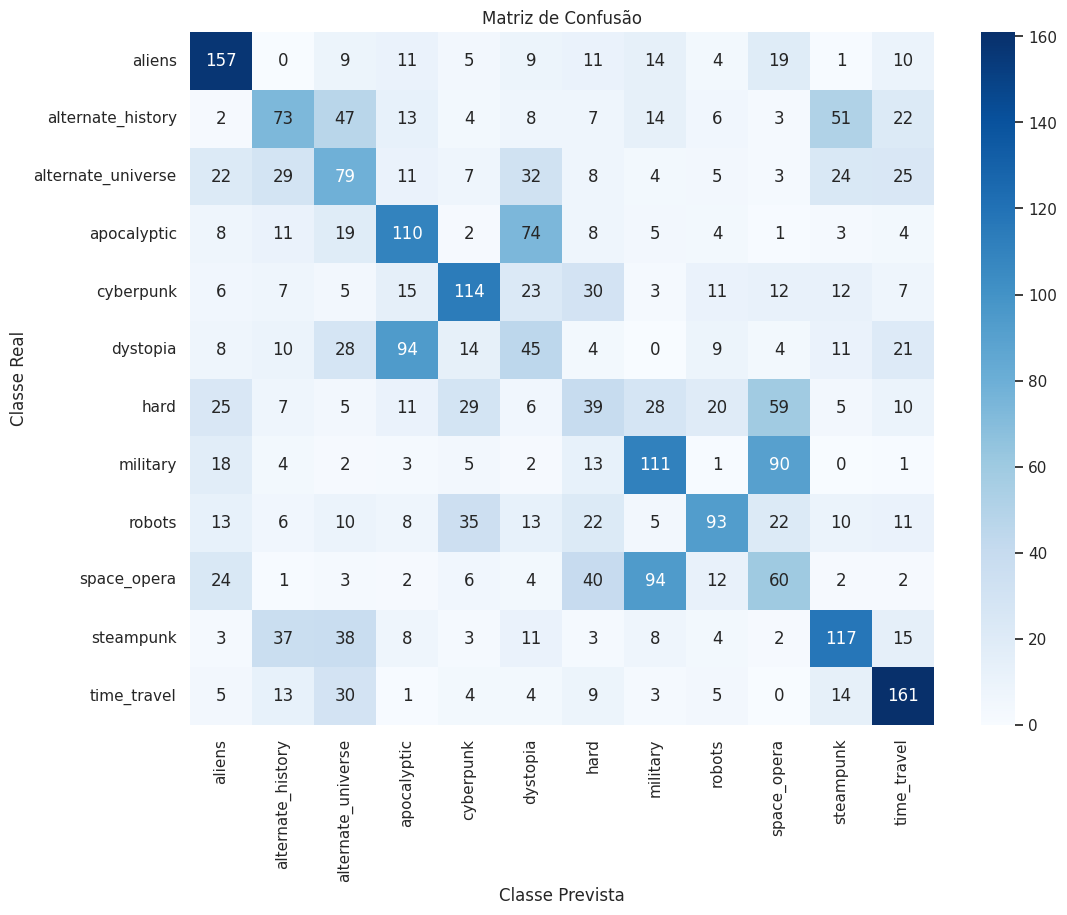

In [ ]:
y_pred = model.predict(X_test)

print(f"Acurácia Geral: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Relatório de Classificação por Subgênero:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Matriz de Confusão Visual
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Matriz de Confusão')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.show()

In [ ]:
def predizer_subgenero(texto_sinopse):
    # Vetorizar a sinopse fornecida
    vetor = tfidf.transform([texto_sinopse])
    # Fazer a predição
    pred_idx = model.predict(vetor)[0]
    # Recuperar o nome da classe
    subgenero = label_encoder.inverse_transform([pred_idx])[0]
    return subgenero

# Exemplo de teste com uma nova sinopse
sinopse_exemplo = "When a rookie marine in powered armor survives an alien ambush on a contested colony world, he uncovers a military command conspiracy that turns his entire mission into a fight against his own government."
subgenero_previsto = predizer_subgenero(sinopse_exemplo)

print(f"Sinopse: {sinopse_exemplo}")
print(f"Subgênero Previsto: {subgenero_previsto}")

Sinopse: When a rookie marine in powered armor survives an alien ambush on a contested colony world, he uncovers a military command conspiracy that turns his entire mission into a fight against his own government.
Subgênero Previsto: military
